# Gaussian process prediction
**Notebook author: Ziad Mosalam**

Companion to *Bayesian Methods for Autonomous Robotics and Intelligent Infrastructure Systems* by Khalid M. Mosalam.

The original inference notebook introduces the Gaussian process formulas. Here we use them to examine a practical question: what happens to an estimated trajectory when observations stop? We compare two covariance assumptions on exactly the same synthetic observations. All times and positions are dimensionless. These are model-conditioned predictions, not field measurements or a calibrated motion model.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('book.mplstyle')
figure_dir = Path('../figures')
figure_dir.mkdir(exist_ok=True)
BLUE, GOLD, TEAL = '#003262', '#B17A00', '#247C86'
INK = '#30363B'


## Observations and assumptions
We observe $y_i=f(t_i)+\epsilon_i$ with independent $\epsilon_i\sim N(0,0.1^2)$. The known synthetic curve is $f(t)=\sin t$. We use a zero prior mean, unit signal variance, and a fixed length scale of one. The hyperparameters are specified rather than fitted. Unlike the near-interpolating call in the introductory notebook, the observation variance here matches the variance used to draw the data.

After $t=5$, there are no observations. The future sine curve is shown only because this is a simulation; it is not supplied to the predictor.

In [2]:
# Match the observations in the book: legacy RandomState seed 42.
rng = np.random.RandomState(42)
t_obs = np.linspace(0.0, 5.0, 20)
noise_sd = 0.1
y_obs = np.sin(t_obs) + noise_sd * rng.randn(t_obs.size)
t_plot = np.linspace(0.0, 8.0, 320)
length_scale = 1.0
signal_variance = 1.0


## Conditioning a Gaussian prior
For $K=K_{oo}+\sigma_\epsilon^2 I$, the latent-function posterior is
$$\mu_* = K_{*o}K^{-1}y, \qquad \Sigma_* = K_{**}-K_{*o}K^{-1}K_{o*}.$$
We solve using a Cholesky factor instead of forming $K^{-1}$. The plotted interval is $\mu_*\pm1.96\sqrt{\operatorname{diag}\Sigma_*}$ for the latent function. A future noisy measurement has the additional variance $\sigma_\epsilon^2$.

The squared-exponential kernel assumes very smooth functions. The Matérn-$3/2$ kernel allows rougher behavior. Both lose correlation with distant observations and therefore return toward the specified prior.

In [3]:
def covariance(t1, t2, kind):
    distance = np.abs(np.asarray(t1)[:, None] - np.asarray(t2)[None, :])
    r = distance / length_scale
    if kind == 'Squared exponential':
        return signal_variance * np.exp(-0.5 * r**2)
    if kind == 'Matérn 3/2':
        a = np.sqrt(3.0) * r
        return signal_variance * (1.0 + a) * np.exp(-a)
    raise ValueError('Unknown covariance function')


def posterior(t_train, y_train, t_test, kind, observation_sd):
    K = covariance(t_train, t_train, kind)
    K += observation_sd**2 * np.eye(len(t_train))
    cross = covariance(t_train, t_test, kind)
    L = np.linalg.cholesky(K)
    alpha = np.linalg.solve(L.T, np.linalg.solve(L, y_train))
    mean = cross.T @ alpha
    V = np.linalg.solve(L, cross)
    cov = covariance(t_test, t_test, kind) - V.T @ V
    cov = 0.5 * (cov + cov.T)
    return mean, cov


kernels = ['Squared exponential', 'Matérn 3/2']
fits = {name: posterior(t_obs, y_obs, t_plot, name, noise_sd)
        for name in kernels}


## What is learned, and what remains assumed?
The upper panels use identical axis limits. The observations constrain the function where data are available, while the prediction becomes sensitive to the covariance choice outside that interval. The lower panel shows latent uncertainty directly. Narrower uncertainty under one kernel is a model consequence, not proof that the model is more accurate.

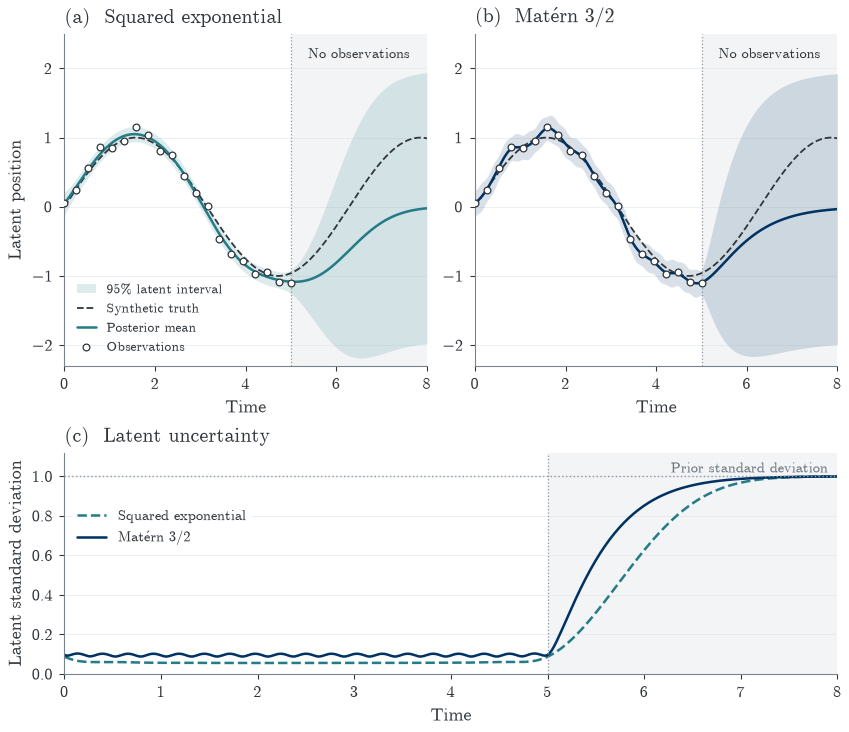

In [4]:
fig = plt.figure(figsize=(6.5, 5.6), layout='constrained')
grid = fig.add_gridspec(2, 2, height_ratios=[1.5, 1.0])
colors = [TEAL, BLUE]
display_names = {'Squared exponential': 'Squared exponential',
                 'Matérn 3/2': r'Mat$\acute{\mathrm{e}}$rn 3/2'}
for j, name in enumerate(kernels):
    ax = fig.add_subplot(grid[0, j])
    mean, cov = fits[name]
    sd = np.sqrt(np.maximum(np.diag(cov), 0.0))
    ax.axvspan(5, 8, color='#F2F4F6', zorder=-2)
    ax.fill_between(t_plot, mean - 1.96*sd, mean + 1.96*sd,
                    color=colors[j], alpha=0.15, linewidth=0, label='95% latent interval')
    ax.plot(t_plot, np.sin(t_plot), '--', color=INK, linewidth=1, label='Synthetic truth')
    ax.plot(t_plot, mean, color=colors[j], label='Posterior mean')
    ax.scatter(t_obs, y_obs, s=14, facecolor='white', edgecolor=INK,
               linewidth=0.7, zorder=4, label='Observations')
    ax.axvline(5, color='#929BA3', linewidth=0.7, linestyle=':')
    ax.text(6.5, 2.15, 'No observations', ha='center', fontsize=8)
    ax.set(xlim=(0, 8), ylim=(-2.3, 2.5), xlabel='Time',
           title=f'({chr(97+j)})  {display_names[name]}')
    ax.grid(axis='y', alpha=0.6)
    if j == 0:
        ax.set_ylabel('Latent position')
        ax.legend(loc='lower left', fontsize=7.5, handlelength=1.4)

ax = fig.add_subplot(grid[1, :])
for name, color, ls in zip(kernels, colors, ['--', '-']):
    mean, cov = fits[name]
    ax.plot(t_plot, np.sqrt(np.maximum(np.diag(cov), 0)), color=color,
            linestyle=ls, label=display_names[name])
ax.axhline(np.sqrt(signal_variance), color='#929BA3', linestyle=':', linewidth=0.8)
ax.text(7.9, 1.02, 'Prior standard deviation', ha='right', fontsize=8, color='#68727B')
ax.axvspan(5, 8, color='#F2F4F6', zorder=-2)
ax.axvline(5, color='#929BA3', linewidth=0.7, linestyle=':')
ax.set(xlim=(0, 8), ylim=(0, 1.12), xlabel='Time', ylabel='Latent standard deviation',
       title='(c)  Latent uncertainty')
ax.legend(loc='upper left', bbox_to_anchor=(0, 0.80), fontsize=8,
          frameon=True, facecolor='white', edgecolor='none', framealpha=1)
ax.grid(axis='y', alpha=0.6)
fig.savefig(figure_dir / 'gaussian-process-prediction.pdf', metadata={'CreationDate': None, 'ModDate': None})
fig.savefig(figure_dir / 'gaussian-process-prediction.png')
plt.show()


## Numerical checks and limits
The covariance must be symmetric positive semidefinite. Conditioning must not increase its diagonal above the prior variance. A direct linear solve and the Cholesky calculation should agree. These checks test the calculation, not whether either kernel describes a real robot's motion.

In [5]:
for name, (mean, cov) in fits.items():
    assert np.allclose(cov, cov.T, atol=1e-12)
    assert np.linalg.eigvalsh(cov).min() > -1e-10
    assert np.diag(cov).min() > -1e-10
    assert np.diag(cov).max() <= signal_variance + 1e-10
    K = covariance(t_obs, t_obs, name) + noise_sd**2 * np.eye(t_obs.size)
    cross = covariance(t_obs, t_plot, name)
    direct_mean = cross.T @ np.linalg.solve(K, y_obs)
    assert np.allclose(mean, direct_mean, rtol=1e-10, atol=1e-10)
print('Both covariance choices pass the conditioning checks.')


Both covariance choices pass the conditioning checks.


The bands are pointwise intervals conditional on the chosen kernel, zero mean, noise variance and hyperparameters. They are not simultaneous trajectory bands. A real forecasting application would need a defensible motion prior, fitted or independently justified hyperparameters, and validation on held-out observations. The original introductory notebook remains unchanged.